# Spherical UMAP: meaningful market representations?

**Question:** can a two-dimensional spherical UMAP representation preserve meaningful, stable structure in equities and FX? Each point is a market day. The markets are fitted separately, using both daily returns and trailing trend descriptors, with separate direction-focused and magnitude-sensitive experiments.

A spherical output is imposed by the method. Unit radius, colorful regions, and a convincing picture do **not** establish that the original market data naturally live on a sphere. Sections 1–14 evaluate neighborhood preservation, descriptive interpretation, and stability. Sections 15–19 additionally compare unconditional mixture density fit and magnitude calibration. No trading strategy is evaluated.

The sphere-fitting notebooks inspire the chronological protocol, synthetic controls, complete-search surrogate calibration, and willingness to report a negative result. Their sphere-versus-plane radial losses are not reused as evidence for an embedding whose radius is fixed by construction.

## 1. Declare the experiment

Normal experiment changes belong in this configuration cell. The saved pilot uses two neighborhood settings, 300 optimization epochs, three layout seeds, and 19 repetitions of each surrogate family. Fitting and surrogate checkpoints make reruns resumable. A completed run is reused only when configuration, source hash, and input hashes match.

Use `GMM/.venv/bin/python` with the additional packages recorded in `requirements_spherical_umap.txt`. The input cell downloads missing public data and verifies existing caches without refreshing. See `REPRODUCING_NOTEBOOKS.md` for a fresh environment and execution commands. A changed scientific configuration creates a new timestamped results directory.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), Path.cwd()/"Thesis", Path.cwd().parent]
             if (p/"spherical_umap.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the workspace root, Thesis, or Thesis/GMM.")
sys.path.insert(0, str(ROOT))
import spherical_umap as experiment
import spherical_umap_report as report
import joblib

CONFIG = dict(
    neighbors=[15, 50], min_dist=0.1, epochs=300,
    selection_seed=42, stability_seeds=[42, 43, 44],
    metric_ks=[5, 15, 50], primary_k=15, pair_samples=20000,
    bootstrap_repeats=1500, bootstrap_blocks=[5, 20, 60],
    surrogate_repeats=19, surrogate_families=["phase", "volatility_envelope"],
    volatility_window=20, noninferiority_margin=0.02,
    workers=4, synthetic_rows=900,
)
REUSE_COMPLETED_RUN = True
MIXTURE_WORKERS = 6
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("UMAP:", experiment.versions()["umap-learn"], "· primary score: held-out training-neighbor recall @15")

/Users/shashwatroy/VSCode Projects/Thesis/GMM/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


UMAP: 0.5.9.post2 · primary score: held-out training-neighbor recall @15


## 2. Verify inputs, calendars, and fixed split dates

The inputs are cached adjusted stock prices and ECB foreign-currency units per EUR. Data hashes are checked against their existing provenance. Equities use 50 log returns. FX uses EUR plus nine other currencies: negative foreign-quote log changes are currency appreciation against EUR; cross-currency demeaning removes that numeraire, and an orthonormal Helmert basis retains the nine independent coordinates.

The original 60/20/20 date boundaries remain fixed for each market. Trend features remove 199 warmup sessions without moving those boundaries. Nothing is filled or silently dropped. The final period has been inspected in earlier research and is labeled **retrospective validation**, not a newly untouched test.

The stock sample is a fixed surviving cohort with current-vintage adjustments. ECB reference fixings are information-only prices, not executable quotes.

In [2]:
# Reconstruct missing public inputs; verify existing caches without refreshing.
sys.path.insert(0, str(ROOT/"GMM"))
import size_direction_experiment as source_data
source_data.acquire_data(refresh=False)
markets, input_record = experiment.load_markets()
track_data = experiment.datasets(markets)
split_rows = []
for track, data in track_data.items():
    frame = data["frame"]
    boundaries = [("Training", frame.index < data["validation_start"]),
                  ("Validation", (frame.index >= data["validation_start"]) & (frame.index < data["test_start"])),
                  ("Retrospective validation", frame.index >= data["test_start"])]
    for label, mask in boundaries:
        dates = frame.index[mask]
        split_rows.append(dict(experiment=track, period=label, observations=len(dates),
                               features=frame.shape[1], start=dates[0].date(), end=dates[-1].date()))
splits = pd.DataFrame(split_rows)
display(splits)
print("Inputs verified:", {name: record["sha256"][:16] for name, record in input_record.items()})

,experiment,period,observations,features,start,end
0,equities/returns,Training,4048,50,2000-01-03,2016-02-04
1,equities/returns,Validation,1350,50,2016-02-05,2021-06-16
2,equities/returns,Retrospective validation,1350,50,2021-06-17,2026-10-30
3,equities/trend,Training,3849,250,2000-10-16,2016-02-04
4,equities/trend,Validation,1350,250,2016-02-05,2021-06-16
5,equities/trend,Retrospective validation,1350,250,2021-06-17,2026-10-30
6,fx/returns,Training,4120,9,2000-01-03,2016-02-08
7,fx/returns,Validation,1373,9,2016-02-09,2021-06-22
8,fx/returns,Retrospective validation,1374,9,2021-06-23,2026-10-30
9,fx/trend,Training,3921,50,2000-10-11,2016-02-08


Inputs verified: {'equities': '4cde6e35d6170590', 'fx': '1bc6b165d4d9b4f6'}


## 3. Define inputs and spherical geometry

For each stock or basket-relative currency, trend coordinates contain trailing **21-, 63-, and 126-session log momentum**, the **price / trailing 200-session average − 1**, and **21-session sample volatility × √252**. Currency price paths are exponentiated cumulative basket-relative strengths. All windows end on the observation date.

Daily returns remain unstandardized. Trend columns are centered and scaled using training statistics. Cosine experiments normalize those rows for direction; Euclidean experiments retain their magnitudes. Norms before row normalization are saved separately. A zero direction vector raises an explicit dated error; it is valid in a Euclidean experiment.

Spherical UMAP optimizes geodesic distances on $S^2$, using periodic latitude $a$ and longitude $b$ with $u=(\cos a\cos b,\cos a\sin b,\sin a)$. The custom Numba distance and gradient use that same convention, and Cartesian distance checks plus finite-difference gradient tests verify the implementation. A three-coordinate unit vector here has **two intrinsic dimensions**; PCA3 has three and is a secondary capacity reference.

References: [UMAP paper](https://arxiv.org/abs/1802.03426), [non-Euclidean embedding documentation](https://umap-learn.readthedocs.io/en/latest/embedding_space.html), and [UMAP distance implementation](https://github.com/lmcinnes/umap/blob/master/umap/distances.py). Trend definitions follow the earlier local research framework; none implies spherical market geometry.

In [3]:
catalog = experiment.feature_catalog(markets)
display(catalog.groupby(["market", "family"]).size().rename("coordinate_count").to_frame())
display(catalog[catalog.family.eq("trend")].assign(descriptor=lambda x: x.feature.str.split("::").str[0])
        .drop_duplicates(["market", "descriptor"])[["market", "descriptor", "definition"]])
angles = np.array([[0., 0.], [0., np.pi/2], [np.pi/2, 0.]])
print("Example Cartesian radii:", np.linalg.norm(experiment.to_xyz(angles), axis=1))
print("Quarter-circle distance:", experiment.sphere_metric(angles[0], angles[1])[0])

coordinate_count
market   family                   
equities returns                50
         trend                 250
fx       returns                 9
         trend                  50

,market,descriptor,definition
50,equities,momentum_21,MSFT: sum of trailing 21 daily log returns
100,equities,momentum_63,MSFT: sum of trailing 63 daily log returns
150,equities,momentum_126,MSFT: sum of trailing 126 daily log returns
200,equities,gap_200,MSFT: exp(cumulative log return) / trailing 20...
250,equities,volatility_21,MSFT: sample std of trailing 21 daily log retu...
309,fx,momentum_21,EUR: sum of trailing 21 daily log returns
319,fx,momentum_63,EUR: sum of trailing 63 daily log returns
329,fx,momentum_126,EUR: sum of trailing 126 daily log returns
339,fx,gap_200,EUR: exp(cumulative log return) / trailing 200...
349,fx,volatility_21,EUR: sample std of trailing 21 daily log retur...


Example Cartesian radii: [1. 1. 1.]
Quarter-circle distance: 1.5707963267948966


## 4. Run or resume the complete pilot

For each of the eight market/input/distance combinations, fit both UMAP neighborhood settings on training data and select by validation recall @15, breaking ties toward 15 neighbors. PCA2 and PCA3 use the same preprocessed inputs. The input neighbor graph is shared between spherical and planar UMAP. Seed comparisons keep that graph fixed and vary the layout seed.

Each held-out query is transformed into the frozen training map. Its original-space training neighbors are compared with its embedding-space training neighbors. Chord and angular neighbor orders agree on the sphere. Trustworthiness uses original-space ranks among those same training candidates; global distance-rank correlation uses 20,000 sampled held-out pairs.

All validation choices are frozen before development refits and retrospective scoring. Paired circular block intervals use 1,500 draws and 5/20/60-session blocks. They are pointwise and conditional on the fitted maps; validation intervals are descriptive after selection.

The complete pilot includes **76 surrogate searches**, each repeating the parameter search over both input families and both distance choices. A fresh run can take substantial time on a laptop; progress and fit caches are saved locally.

In [4]:
RUN_DIR = None
if REUSE_COMPLETED_RUN:
    for candidate in sorted((ROOT/"spherical_umap_results").glob("*/report_bundle.joblib"), reverse=True):
        protocol_path = candidate.parent/"protocol.json"
        if not protocol_path.exists():
            continue
        protocol = json.loads(protocol_path.read_text())
        inputs_match = all(protocol.get("inputs", {}).get(k, {}).get("sha256") == v["sha256"]
                           for k, v in input_record.items())
        if protocol.get("config") == CONFIG and protocol.get("code_sha256") == experiment.sha(experiment.__file__) and inputs_match and protocol.get("versions") == experiment.versions():
            RUN_DIR = candidate.parent
            break
if RUN_DIR is None:
    bundle = experiment.run_experiment(CONFIG)
    RUN_DIR = Path(bundle["run_dir"])
else:
    bundle = joblib.load(RUN_DIR/"report_bundle.joblib")
    print("Reused verified completed experiment:", RUN_DIR.name)
print("Run directory:", RUN_DIR)
display(pd.DataFrame([dict(component=k, version=v) for k, v in experiment.versions().items()]))

Reused verified completed experiment: 20261104T212220_256059Z
Run directory: /Users/shashwatroy/VSCode Projects/Thesis/spherical_umap_results/20261104T212220_256059Z


,component,version
0,python,3.11.13
1,numpy,1.26.4
2,pandas,2.3.3
3,scipy,1.12.0
4,scikit-learn,1.9.1
5,umap-learn,0.5.9.post2
6,numba,0.61.2
7,pynndescent,0.5.13
8,nbclient,0.10.2
9,matplotlib,3.11.2


## 5. Primary scorecard

Positive differences favor spherical UMAP. The practical noninferiority margin is **−2 percentage points of recall @15**. “Comparable” means the lower interval bound stays above that margin; it does not establish equality. “Degradation” requires the entire interval below the margin. Other results remain inconclusive.

The error bars use 20-session blocks. These are separate experiments with different input spaces; their absolute recall values should not be interpreted as a ranking of equities versus FX. Surrogate tail fractions calibrate validation gains and are not final-period significance tests.

,track,metric,test_gain,lower,upper,conclusion,tail_phase,tail_volatility_envelope
0,equities/returns,cosine,-0.0417,-0.0480,-0.0347,Spherical degradation,1.0,1.00
1,equities/returns,euclidean,-0.0200,-0.0240,-0.0163,Inconclusive comparison,1.0,1.00
2,equities/trend,cosine,-0.2841,-0.3078,-0.2621,Spherical degradation,1.0,1.00
3,equities/trend,euclidean,-0.3351,-0.3583,-0.3130,Spherical degradation,1.0,1.00
4,fx/returns,cosine,-0.0640,-0.0701,-0.0578,Spherical degradation,1.0,1.00
5,fx/returns,euclidean,-0.0393,-0.0446,-0.0331,Spherical degradation,0.9,0.95
6,fx/trend,cosine,-0.3480,-0.3698,-0.3264,Spherical degradation,1.0,1.00
7,fx/trend,euclidean,-0.3319,-0.3523,-0.3100,Spherical degradation,1.0,1.00


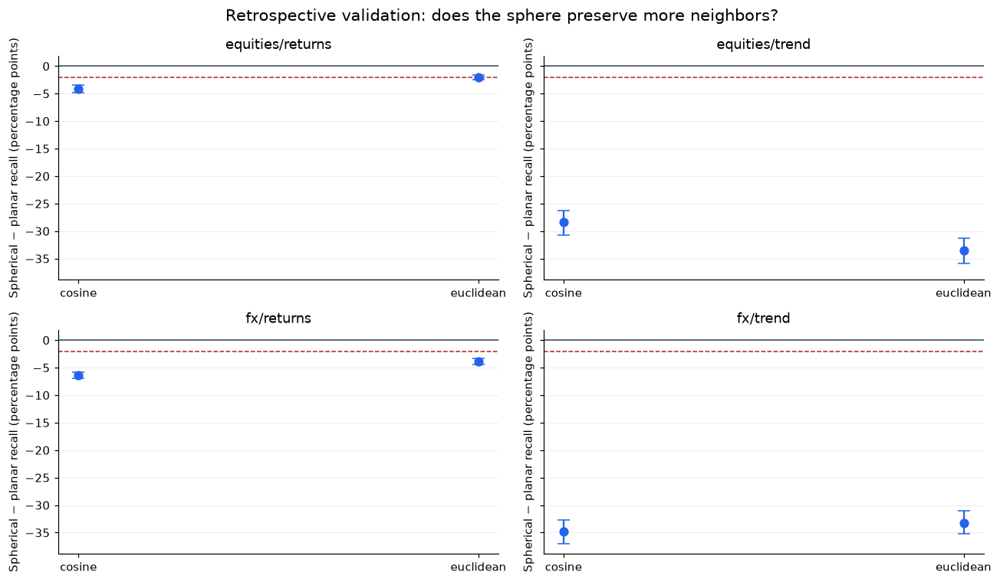

,experiment,random_neighbor_recall_15
0,equities/returns/cosine,0.0028
1,equities/returns/euclidean,0.0028
2,equities/trend/cosine,0.0029
3,equities/trend/euclidean,0.0029
4,fx/returns/cosine,0.0027
5,fx/returns/euclidean,0.0027
6,fx/trend/cosine,0.0028
7,fx/trend/euclidean,0.0028


In [5]:
cards = bundle["scorecards"].copy()
display(cards[["track", "metric", "test_gain", "lower", "upper", "conclusion", "tail_phase", "tail_volatility_envelope"]].round(4))
report.summary(bundle)
chance = []
for key, result in bundle["results"].items():
    n = len(result["test"]["prepared"]["x"])
    chance.append(dict(experiment=key, random_neighbor_recall_15=15/n))
display(pd.DataFrame(chance).round(4))

## 6. Equities · returns

Daily return inputs compare same-day cross-asset movement patterns. Equity direction is the equal-weight stock return, breadth is the fraction of positive stock returns, and sector contrasts subtract the market mean.

The table includes local recall, inductive trustworthiness, and global distance-rank correlation. Plot rows compare spherical and planar maps under the same input metric. Date and market-descriptor colors are applied after fitting. Each map is an independently fitted coordinate system, so absolute angular positions do not have a shared meaning across panels.

,metric,method,recall_5,recall_15,recall_50,trustworthiness_15,distance_rank_correlation
0,cosine,Spherical UMAP,0.0233,0.0520,0.1028,0.8131,0.6991
1,cosine,Planar UMAP,0.0468,0.0938,0.1321,0.8473,0.7159
2,cosine,PCA2,0.0098,0.0231,0.0583,0.7777,0.6944
3,cosine,PCA3,0.0243,0.0477,0.0989,0.8403,0.7536
4,euclidean,Spherical UMAP,0.0197,0.0473,0.0999,0.7584,0.3655
5,euclidean,Planar UMAP,0.0353,0.0673,0.1135,0.7587,0.5802
6,euclidean,PCA2,0.0196,0.0449,0.1012,0.7790,0.6999
7,euclidean,PCA3,0.0379,0.0739,0.1516,0.8144,0.7705


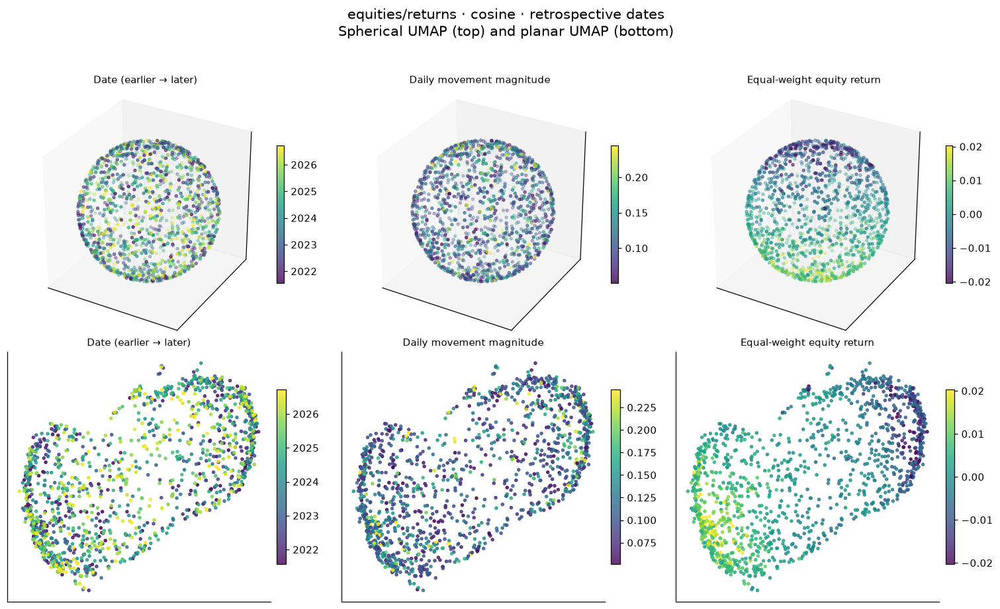

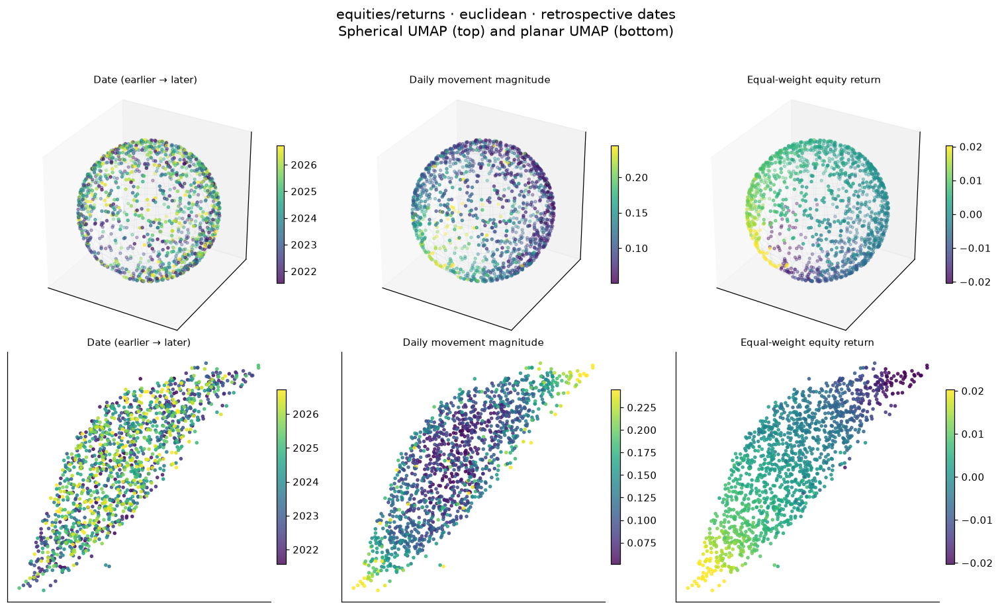

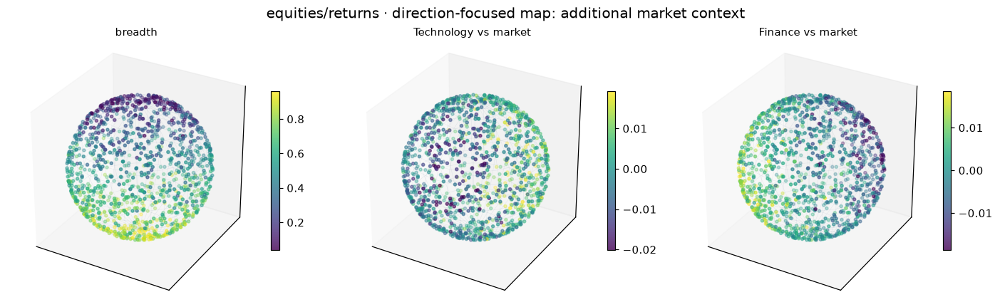

In [6]:
display(report.quality(bundle, "equities/returns").round(4))
report.maps(bundle, "equities/returns", "cosine")
report.maps(bundle, "equities/returns", "euclidean")
report.market_context(bundle, "equities/returns")

### Descriptive interpretation of equities/returns

For each descriptor, use a held-out day's 15 embedding neighbors among training dates to compute a local descriptor mean. The heatmap shows **1 − local squared error / error around the training descriptor mean**. Negative values are allowed. This is a measure of same-day descriptive coherence, not a future prediction. Input-derived descriptors are not independent validation evidence and do not select the maps.

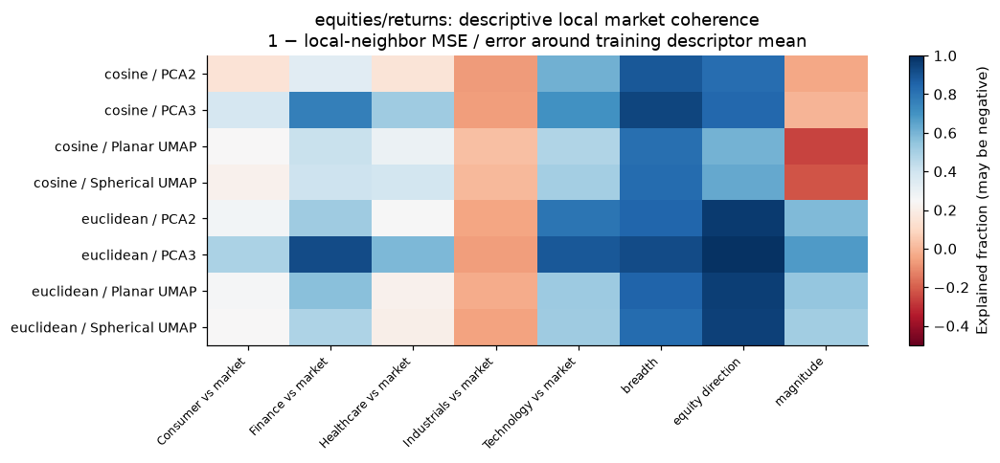

In [7]:
report.descriptor_heatmap(bundle, "equities/returns")

## 7. Equities · trend

Trailing trend descriptors summarize direction, position, and risk. Shared rolling windows can make adjacent days similar; persistence alone is not independent economic validation. Equity direction is the equal-weight stock return, breadth is the fraction of positive stock returns, and sector contrasts subtract the market mean.

The table includes local recall, inductive trustworthiness, and global distance-rank correlation. Plot rows compare spherical and planar maps under the same input metric. Date and market-descriptor colors are applied after fitting. Each map is an independently fitted coordinate system, so absolute angular positions do not have a shared meaning across panels.

,metric,method,recall_5,recall_15,recall_50,trustworthiness_15,distance_rank_correlation
0,cosine,Spherical UMAP,0.0486,0.0983,0.1262,0.6164,0.0262
1,cosine,Planar UMAP,0.2237,0.3824,0.2957,0.9387,0.0600
2,cosine,PCA2,0.0037,0.0102,0.0273,0.6802,0.5467
3,cosine,PCA3,0.0113,0.0205,0.0423,0.7310,0.5986
4,euclidean,Spherical UMAP,0.0409,0.0958,0.1241,0.5901,0.0342
5,euclidean,Planar UMAP,0.2511,0.4309,0.3167,0.9401,0.0307
6,euclidean,PCA2,0.0071,0.0212,0.0499,0.7145,0.5082
7,euclidean,PCA3,0.0179,0.0400,0.0766,0.7612,0.5709


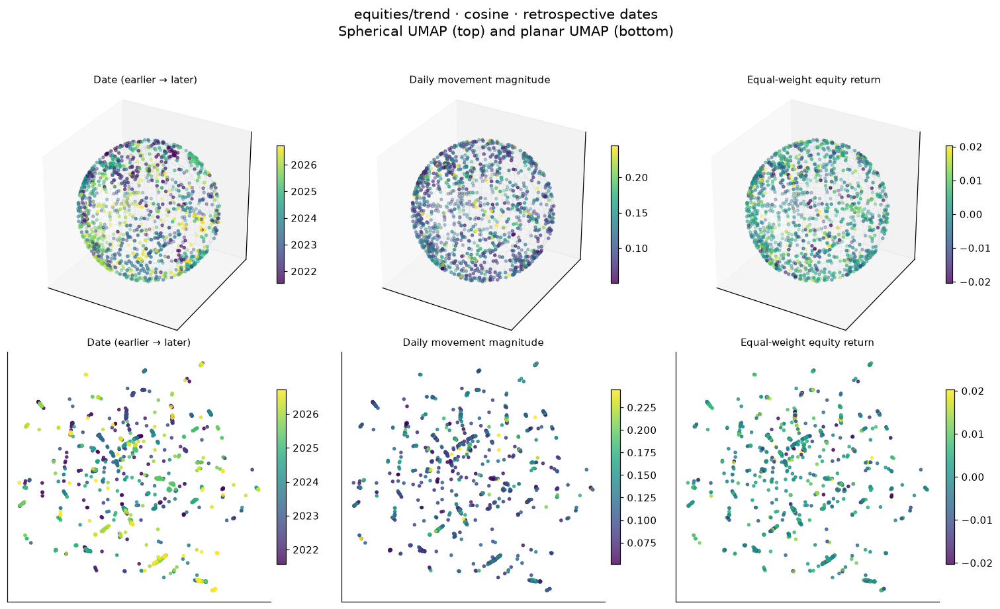

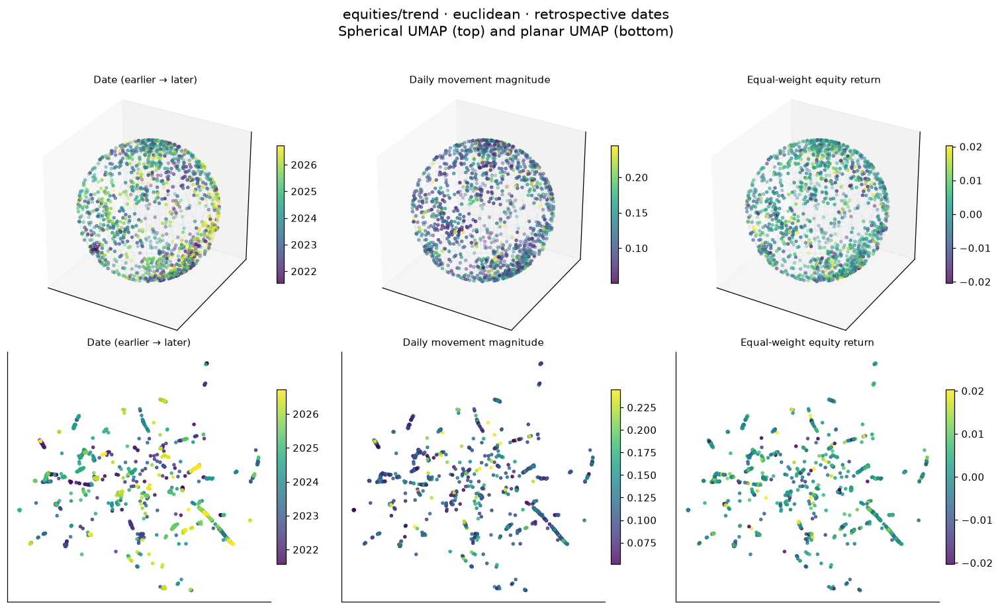

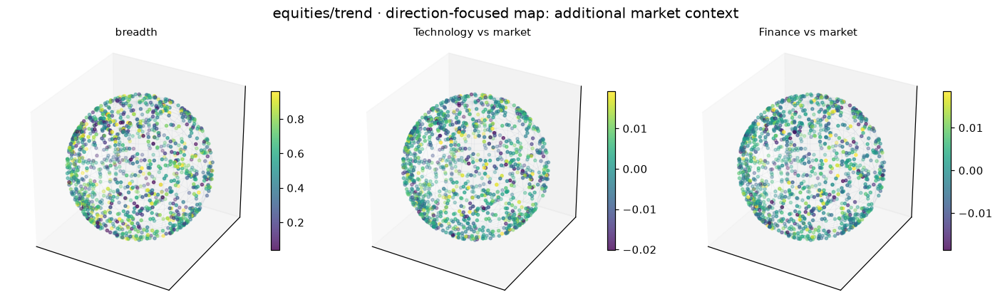

In [8]:
display(report.quality(bundle, "equities/trend").round(4))
report.maps(bundle, "equities/trend", "cosine")
report.maps(bundle, "equities/trend", "euclidean")
report.market_context(bundle, "equities/trend")

### Descriptive interpretation of equities/trend

For each descriptor, use a held-out day's 15 embedding neighbors among training dates to compute a local descriptor mean. The heatmap shows **1 − local squared error / error around the training descriptor mean**. Negative values are allowed. This is a measure of same-day descriptive coherence, not a future prediction. Input-derived descriptors are not independent validation evidence and do not select the maps.

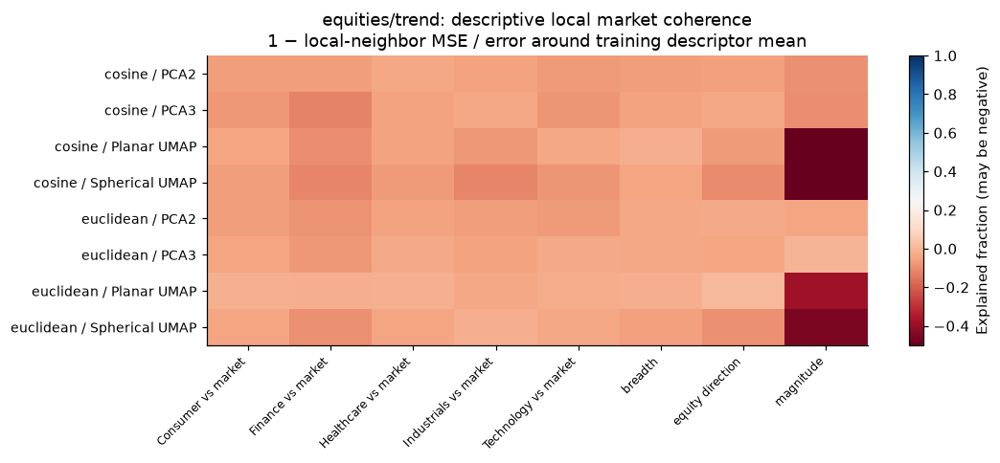

In [9]:
report.descriptor_heatmap(bundle, "equities/trend")

## 8. Fx · returns

Daily return inputs compare same-day cross-asset movement patterns. Currency strengths are relative to the equal-weight geometric currency basket. USD/EUR/JPY colors are descriptive; a positive sign means appreciation against that basket.

The table includes local recall, inductive trustworthiness, and global distance-rank correlation. Plot rows compare spherical and planar maps under the same input metric. Date and market-descriptor colors are applied after fitting. Each map is an independently fitted coordinate system, so absolute angular positions do not have a shared meaning across panels.

,metric,method,recall_5,recall_15,recall_50,trustworthiness_15,distance_rank_correlation
0,cosine,Spherical UMAP,0.0346,0.0772,0.1511,0.8688,0.7817
1,cosine,Planar UMAP,0.0836,0.1413,0.2050,0.8960,0.6826
2,cosine,PCA2,0.0207,0.0449,0.1007,0.7855,0.6781
3,cosine,PCA3,0.0603,0.1087,0.1951,0.8746,0.7931
4,euclidean,Spherical UMAP,0.0249,0.0601,0.1152,0.7658,0.3820
5,euclidean,Planar UMAP,0.0540,0.0994,0.1505,0.8263,0.6404
6,euclidean,PCA2,0.0226,0.0537,0.1162,0.8077,0.7912
7,euclidean,PCA3,0.0699,0.1241,0.2245,0.8939,0.8895


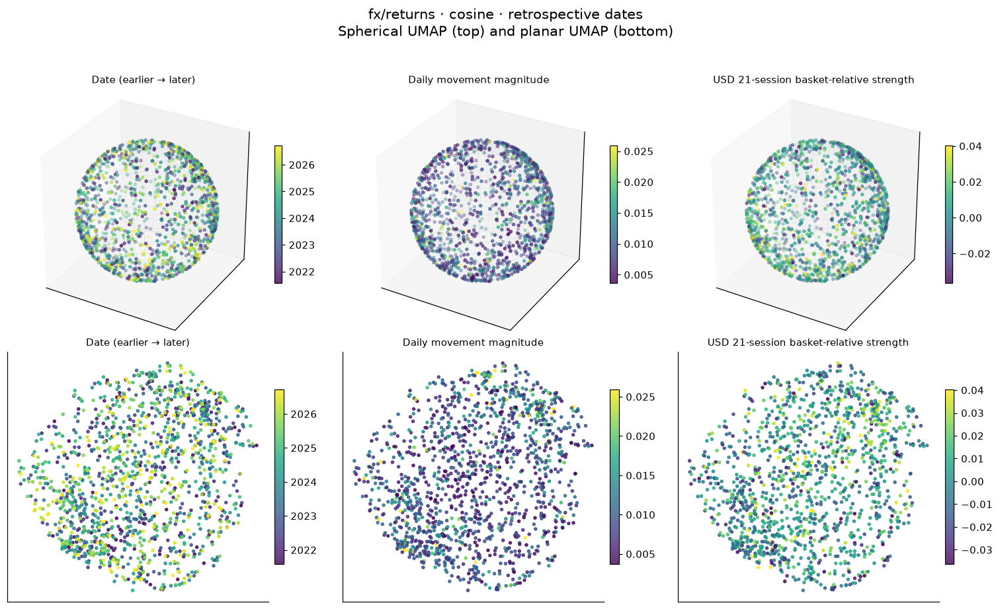

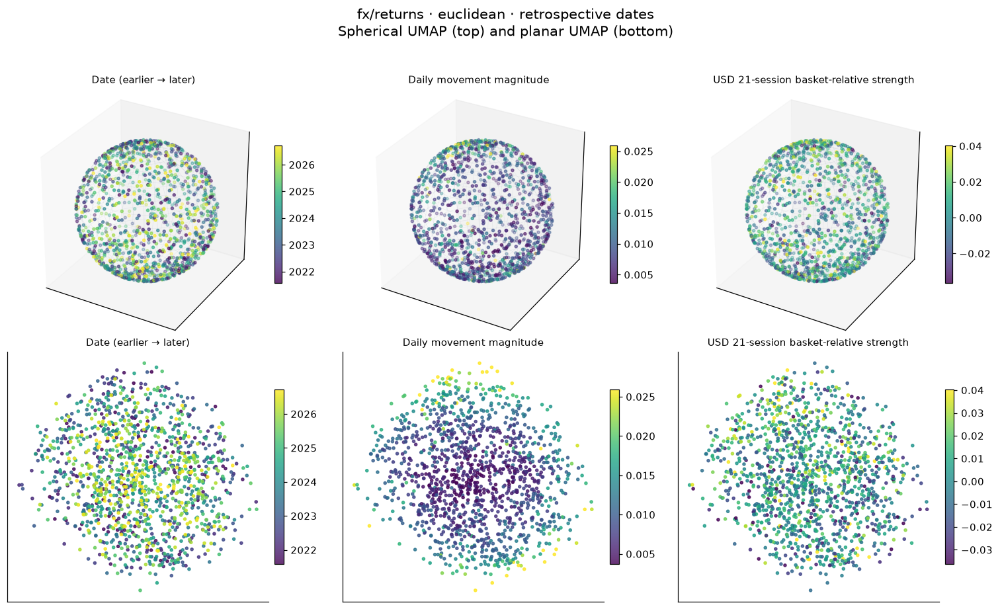

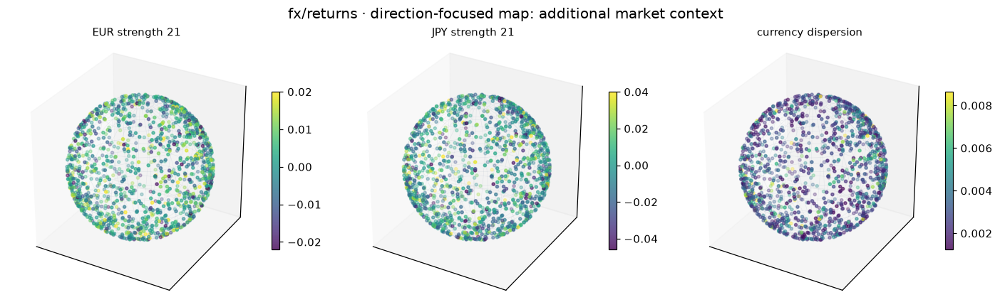

In [10]:
display(report.quality(bundle, "fx/returns").round(4))
report.maps(bundle, "fx/returns", "cosine")
report.maps(bundle, "fx/returns", "euclidean")
report.market_context(bundle, "fx/returns")

### Descriptive interpretation of fx/returns

For each descriptor, use a held-out day's 15 embedding neighbors among training dates to compute a local descriptor mean. The heatmap shows **1 − local squared error / error around the training descriptor mean**. Negative values are allowed. This is a measure of same-day descriptive coherence, not a future prediction. Input-derived descriptors are not independent validation evidence and do not select the maps.

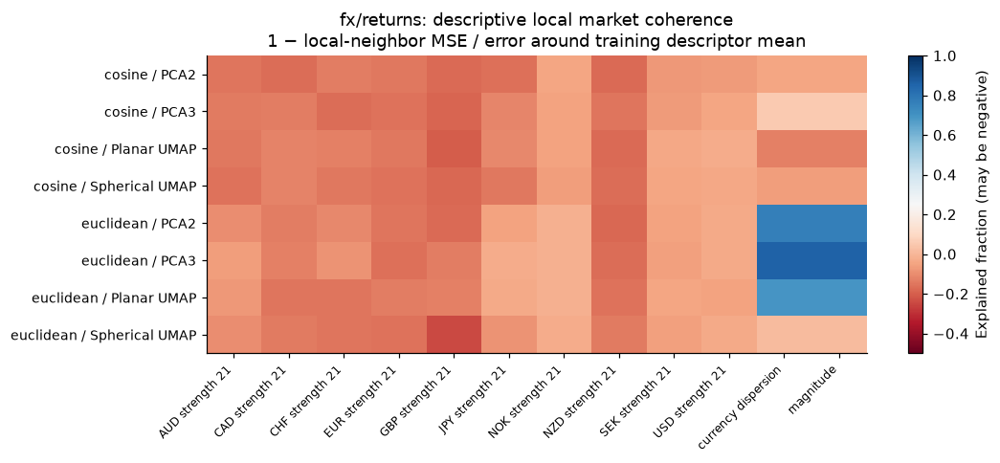

In [11]:
report.descriptor_heatmap(bundle, "fx/returns")

## 9. Fx · trend

Trailing trend descriptors summarize direction, position, and risk. Shared rolling windows can make adjacent days similar; persistence alone is not independent economic validation. Currency strengths are relative to the equal-weight geometric currency basket. USD/EUR/JPY colors are descriptive; a positive sign means appreciation against that basket.

The table includes local recall, inductive trustworthiness, and global distance-rank correlation. Plot rows compare spherical and planar maps under the same input metric. Date and market-descriptor colors are applied after fitting. Each map is an independently fitted coordinate system, so absolute angular positions do not have a shared meaning across panels.

,metric,method,recall_5,recall_15,recall_50,trustworthiness_15,distance_rank_correlation
0,cosine,Spherical UMAP,0.0482,0.1073,0.1331,0.6193,0.0681
1,cosine,Planar UMAP,0.3180,0.4553,0.3279,0.9471,0.0880
2,cosine,PCA2,0.0087,0.0281,0.0704,0.7515,0.6865
3,cosine,PCA3,0.0256,0.0569,0.1247,0.8708,0.7815
4,euclidean,Spherical UMAP,0.0447,0.0942,0.1177,0.5933,0.1398
5,euclidean,Planar UMAP,0.2879,0.4262,0.2893,0.9241,0.1447
6,euclidean,PCA2,0.0090,0.0269,0.0786,0.7494,0.7570
7,euclidean,PCA3,0.0269,0.0587,0.1407,0.8719,0.8237


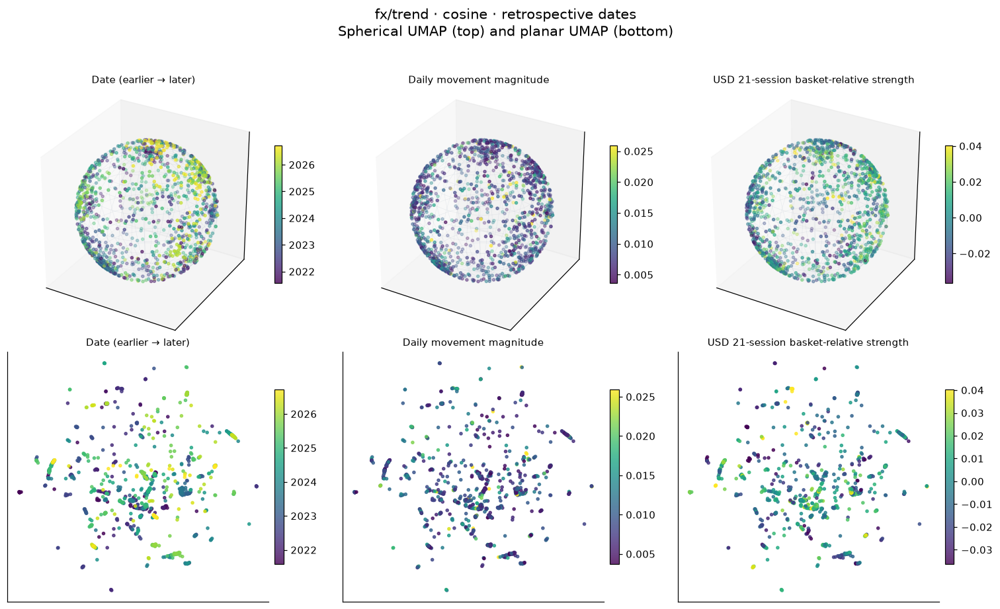

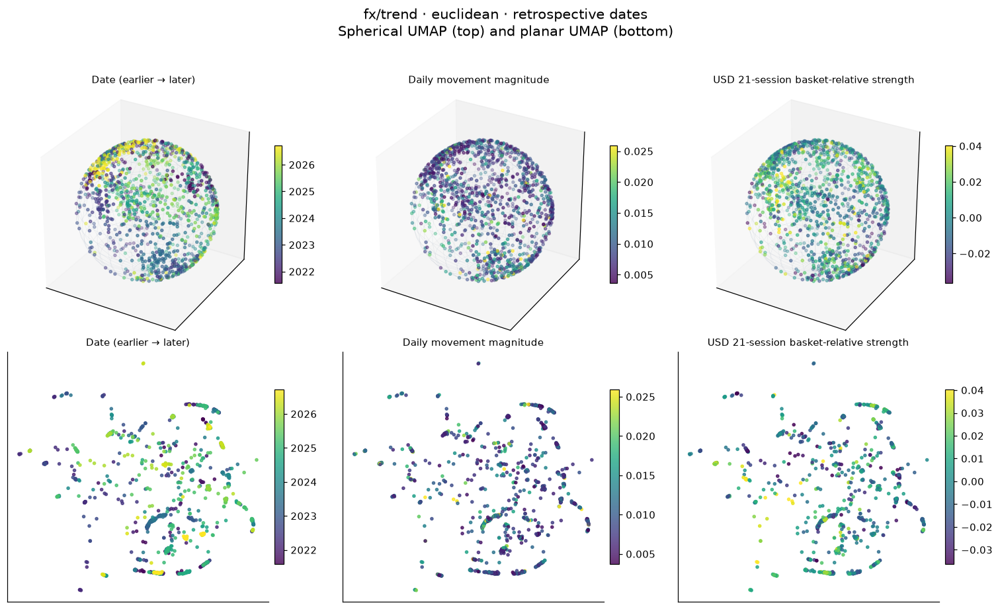

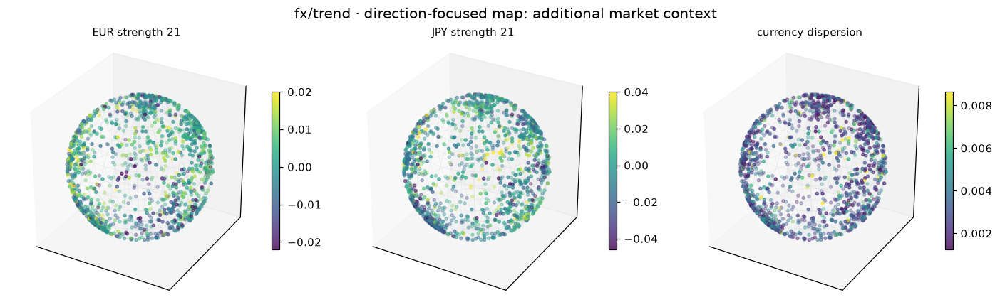

In [12]:
display(report.quality(bundle, "fx/trend").round(4))
report.maps(bundle, "fx/trend", "cosine")
report.maps(bundle, "fx/trend", "euclidean")
report.market_context(bundle, "fx/trend")

### Descriptive interpretation of fx/trend

For each descriptor, use a held-out day's 15 embedding neighbors among training dates to compute a local descriptor mean. The heatmap shows **1 − local squared error / error around the training descriptor mean**. Negative values are allowed. This is a measure of same-day descriptive coherence, not a future prediction. Input-derived descriptors are not independent validation evidence and do not select the maps.

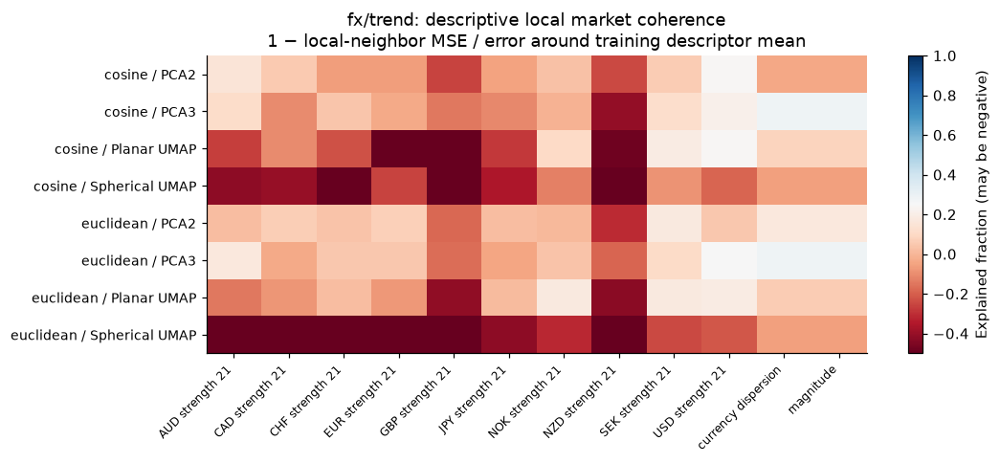

In [13]:
report.descriptor_heatmap(bundle, "fx/trend")

## 10. Stability across seeds and time

Neighbor overlap measures whether independent layout seeds attach the same validation observations to the same training dates. Seed 42 compared with itself is omitted from the plot. Spherical alignment fits an orthogonal rotation/reflection on training anchors only, then measures validation angular disagreement in radians.

The three time panels use consecutive validation thirds with one frozen training map. They measure performance drift, rather than providing three independent replications. Stable colors or chronology do not substitute for stable neighborhoods.

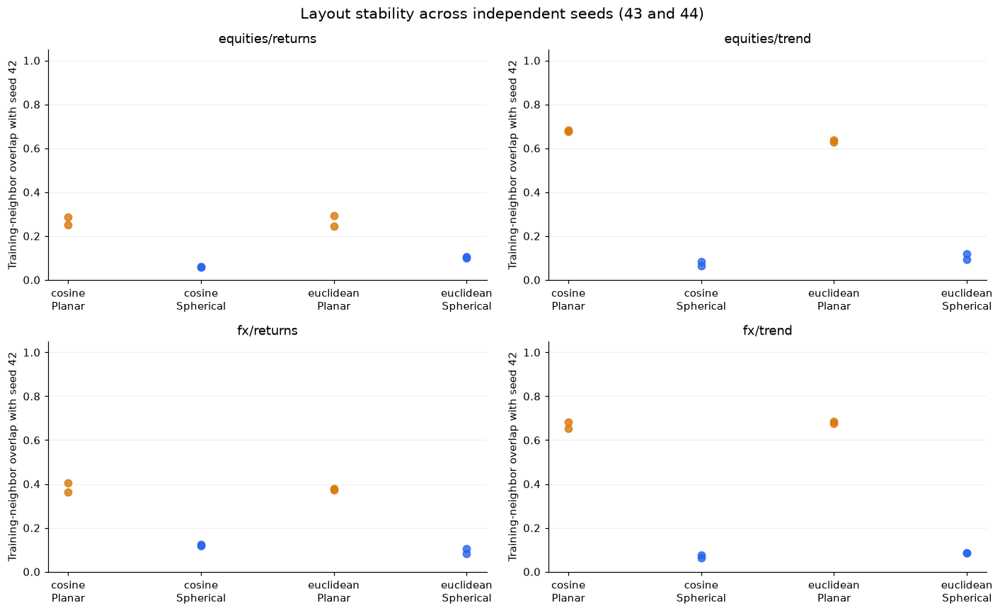

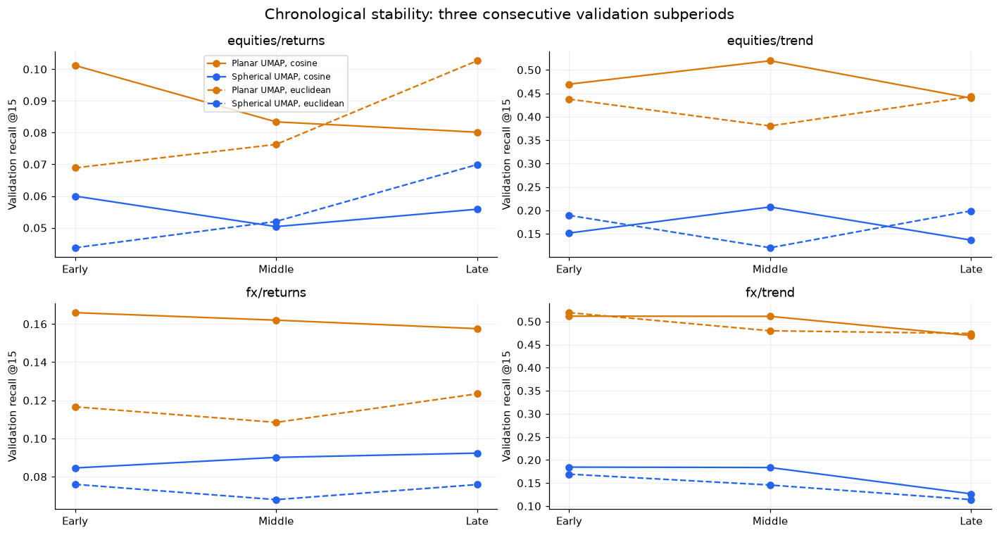

,track,metric,method,seed,neighbor_overlap,aligned_angular_error,recall_15
1,equities/returns,cosine,Spherical UMAP,43,0.0560,0.6704,0.0559
2,equities/returns,cosine,Spherical UMAP,44,0.0610,0.5754,0.0562
4,equities/returns,cosine,Planar UMAP,43,0.2505,NaN,0.0856
5,equities/returns,cosine,Planar UMAP,44,0.2875,NaN,0.0837
7,equities/returns,euclidean,Spherical UMAP,43,0.1002,0.4007,0.0633
8,equities/returns,euclidean,Spherical UMAP,44,0.1043,0.3636,0.0609
10,equities/returns,euclidean,Planar UMAP,43,0.2452,NaN,0.0782
11,equities/returns,euclidean,Planar UMAP,44,0.2938,NaN,0.0811
13,equities/trend,cosine,Spherical UMAP,43,0.0848,1.4923,0.1560
14,equities/trend,cosine,Spherical UMAP,44,0.0630,1.5731,0.1191


,track,metric,block,mean,lower,upper
60,equities/returns,cosine,5,-0.0417,-0.0481,-0.0351
61,equities/returns,cosine,20,-0.0417,-0.0480,-0.0347
62,equities/returns,cosine,60,-0.0417,-0.0489,-0.0345
168,equities/returns,euclidean,5,-0.0200,-0.0239,-0.0160
169,equities/returns,euclidean,20,-0.0200,-0.0240,-0.0163
170,equities/returns,euclidean,60,-0.0200,-0.0235,-0.0168
276,equities/trend,cosine,5,-0.2841,-0.3009,-0.2672
277,equities/trend,cosine,20,-0.2841,-0.3078,-0.2621
278,equities/trend,cosine,60,-0.2841,-0.3135,-0.2538
384,equities/trend,euclidean,5,-0.3351,-0.3526,-0.3185


In [14]:
report.stability(bundle)
stability = bundle["tables"]["seed_stability"]
display(stability[stability.seed.ne(42)][["track", "metric", "method", "seed", "neighbor_overlap", "aligned_angular_error", "recall_15"]].round(4))
contrasts = bundle["tables"]["comparisons"]
display(contrasts.query("stage == 'retrospective_test' and baseline == 'Planar UMAP' and score == 'recall_15'")
        [["track", "metric", "block", "mean", "lower", "upper"]].round(4))

## 11. Can simpler temporal structure explain the gain?

**Shared-phase controls** preserve multivariate cross-spectra, means, and covariance within each randomized segment. **Volatility-envelope controls** remove a common trailing RMS envelope, randomize residual phases, and restore that envelope; cross-spectral preservation is approximate and its error is reported.

Training and validation daily inputs are randomized separately, preventing held-out values from entering surrogate training through a Fourier transform. Their artificial boundary can affect subsequent rolling descriptors and limits the null model. FX controls are generated in independent contrasts and reconstructed into basket-relative currency strengths before trend features are rebuilt.

Every control repeats the entire two-setting search for both input families and both input distances. Its maximum spherical-minus-planar recall gain calibrates the observed candidates within that market. An unresolved numerical search counts as an infinite maximum, rather than being silently discarded. With 19 repetitions, the smallest possible conditional tail fraction is **0.05**. These are conditional falsification controls, not universal nonspherical null distributions or proof of topology.

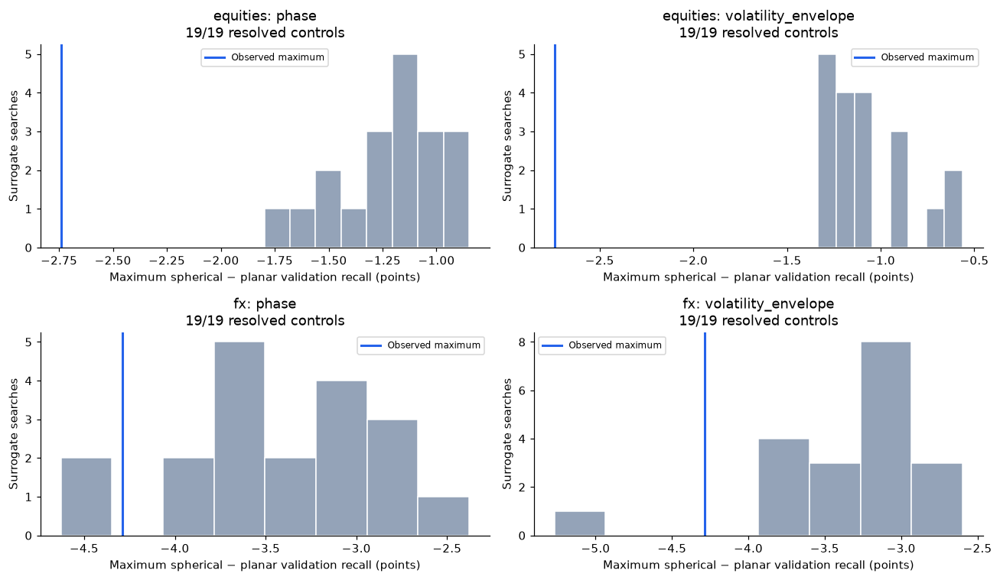

repetitions  resolved  \
market   family                                       
equities phase                         19        19   
         volatility_envelope           19        19   
fx       phase                         19        19   
         volatility_envelope           19        19   

                              median_spectral_error_train  \
market   family                                             
equities phase                                   0.000000   
         volatility_envelope                     0.758852   
fx       phase                                   0.000000   
         volatility_envelope                     0.600268   

                              median_spectral_error_validation  \
market   family                                                  
equities phase                                        0.000000   
         volatility_envelope                          0.784065   
fx       phase                                        0.000000   
         volatility_envelope                          0.482836   

                              median_maximum_gain  
market   family                                    
equities phase                          -0.012049  
         volatility_envelope            -0.011309  
fx       phase                          -0.033309  
         volatility_envelope            -0.032338

,track,metric,validation_gain,tail_phase,tail_volatility_envelope,unresolved_phase,unresolved_volatility_envelope
0,equities/returns,cosine,-0.0328,1.0,1.00,0,0
1,equities/returns,euclidean,-0.0274,1.0,1.00,0,0
2,equities/trend,cosine,-0.3111,1.0,1.00,0,0
3,equities/trend,euclidean,-0.2508,1.0,1.00,0,0
4,fx/returns,cosine,-0.0728,1.0,1.00,0,0
5,fx/returns,euclidean,-0.0429,0.9,0.95,0,0
6,fx/trend,cosine,-0.3327,1.0,1.00,0,0
7,fx/trend,euclidean,-0.3482,1.0,1.00,0,0


In [15]:
controls = report.control_plot(bundle)
display(controls.groupby(["market", "family"]).agg(
    repetitions=("repeat", "count"), resolved=("status", lambda x: int(x.eq("ok").sum())),
    median_spectral_error_train=("spectral_error_train", "median"),
    median_spectral_error_validation=("spectral_error_validation", "median"),
    median_maximum_gain=("maximum_gain", "median")).round(6))
display(bundle["scorecards"][["track", "metric", "validation_gain", "tail_phase", "tail_volatility_envelope", "unresolved_phase", "unresolved_volatility_envelope"]].round(4))

## 12. Synthetic examples: the sphere is imposed

Generate a noisy spherical surface, a plane, and a Gaussian cloud, each observed through the same higher-dimensional linear map. Apply the same train/validation selection process. Every spherical UMAP output has unit radius, including the nonspherical examples. Recovery is assessed by preserved neighborhoods and comparison with unconstrained alternatives.

Finite synthetic samples and this parameter grid are checks of the implementation, not a universal demonstration that UMAP identifies a source manifold. Unit radius also fixes the output-distance scale and finite sphere area; this pilot does not tune that scale. Performance differences can reflect this constraint and optimization, as well as the data structure. This pilot evaluates S², not higher-dimensional hyperspheres or learned output radii.

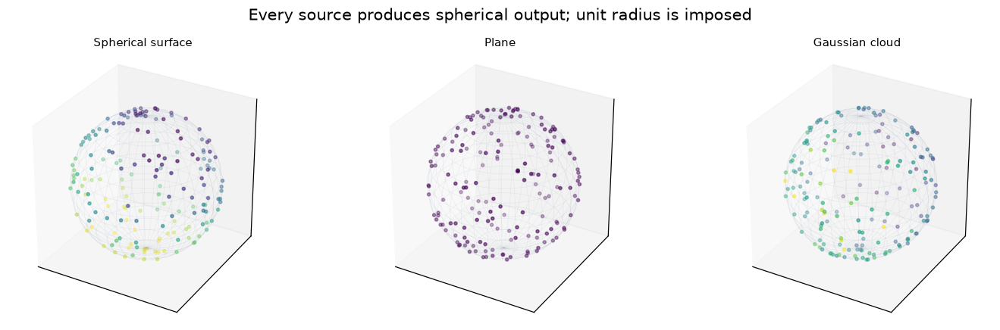

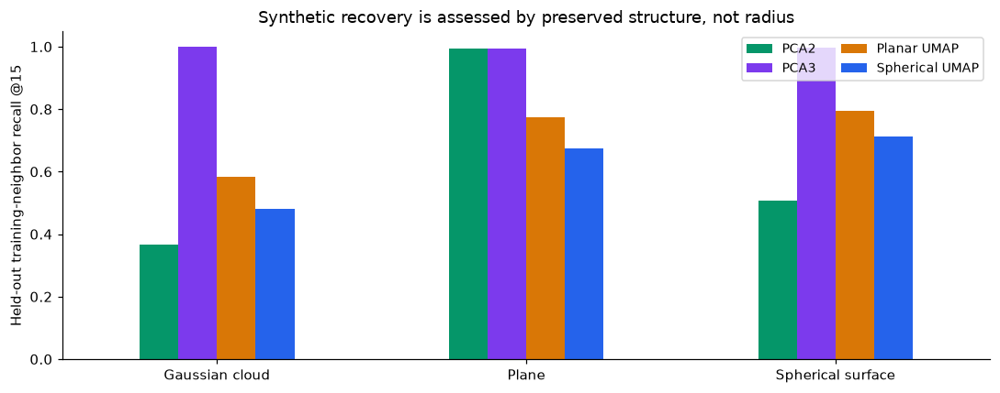

,source,method,recall_15,output_radius_error
0,Spherical surface,Spherical UMAP,0.71259,0.0
1,Spherical surface,Planar UMAP,0.79370,NaN
2,Spherical surface,PCA2,0.50852,NaN
3,Spherical surface,PCA3,0.99815,NaN
4,Plane,Spherical UMAP,0.67444,0.0
5,Plane,Planar UMAP,0.77296,NaN
6,Plane,PCA2,0.99259,NaN
7,Plane,PCA3,0.99370,NaN
8,Gaussian cloud,Spherical UMAP,0.48037,0.0
9,Gaussian cloud,Planar UMAP,0.58222,NaN


In [16]:
report.synthetic_plot(bundle)
display(bundle["synthetic"].round(5))

## 13. Conclusions from this executed pilot

The following statements are generated from the saved scorecards and seed diagnostics. Improvement in an imposed spherical representation would support its practical use under this protocol; it would not establish natural spherical geometry. Failure is a valid result.

In [17]:
conclusion_text = report.conclusions(bundle)
display(Markdown(conclusion_text))
(RUN_DIR/"conclusions.md").write_text(conclusion_text + "\n")

- **equities/returns** — **cosine:** spherical degradation; recall gain -4.17 points (95% interval -4.80 to -3.47); mean seed-neighbor overlap 0.06. Search-calibrated validation tail fractions: phase 1.00, envelope 1.00. **euclidean:** inconclusive comparison; recall gain -2.00 points (95% interval -2.40 to -1.63); mean seed-neighbor overlap 0.10. Search-calibrated validation tail fractions: phase 1.00, envelope 1.00.

- **equities/trend** — **cosine:** spherical degradation; recall gain -28.41 points (95% interval -30.78 to -26.21); mean seed-neighbor overlap 0.07. Search-calibrated validation tail fractions: phase 1.00, envelope 1.00. **euclidean:** spherical degradation; recall gain -33.51 points (95% interval -35.83 to -31.30); mean seed-neighbor overlap 0.11. Search-calibrated validation tail fractions: phase 1.00, envelope 1.00.

- **fx/returns** — **cosine:** spherical degradation; recall gain -6.40 points (95% interval -7.01 to -5.78); mean seed-neighbor overlap 0.12. Search-calibrated validation tail fractions: phase 1.00, envelope 1.00. **euclidean:** spherical degradation; recall gain -3.93 points (95% interval -4.46 to -3.31); mean seed-neighbor overlap 0.09. Search-calibrated validation tail fractions: phase 0.90, envelope 0.95.

- **fx/trend** — **cosine:** spherical degradation; recall gain -34.80 points (95% interval -36.98 to -32.64); mean seed-neighbor overlap 0.07. Search-calibrated validation tail fractions: phase 1.00, envelope 1.00. **euclidean:** spherical degradation; recall gain -33.19 points (95% interval -35.23 to -31.00); mean seed-neighbor overlap 0.09. Search-calibrated validation tail fractions: phase 1.00, envelope 1.00.


**Synthetic calibration:** on the known spherical source, recall is 71.3% for spherical UMAP and 79.4% for planar UMAP. This limits the market conclusions to the chosen unit-radius embedding setup and optimization budget.


The intervals are pointwise and conditional on the fitted models. Validation selection, finite surrogate controls, overlapping rolling windows, and historical reuse limit inference. Descriptive market colors and local coherence reuse information from the inputs. They explain the representations; they are not independent evidence of natural spheres or forecast value.

2276

## 14. Reproduction and saved artifacts

The run directory contains the protocol, provenance and dependency versions; fixed split dates and feature catalog; the frozen selection manifest; trial ledgers; per-date scores and input norms; query coordinates (Cartesian values, canonical latitude/longitude, and original optimizer angles); bootstrap comparisons; seed and period diagnostics; descriptor profiles; full surrogate trials and maxima; synthetic metrics; and the numerical report bundle. Figures are exported as PNG and PDF as well as embedded below their notebook cells.

Fit caches are keyed by training/query arrays, fit settings, engine source, and dependency versions. Control caches additionally include the complete experiment source and configuration. Fit warnings are retained; numerical exceptions are saved in the failure cache. No failed candidate is silently removed from a declared search. The initial concurrent cache-read incident and its resolution are retained in `cache_io_correction.json`; the final report uses complete, rescored controls.

To reproduce, install the additional dependencies into the existing Python 3.11 environment and run all notebook cells. Set `REUSE_COMPLETED_RUN=False` to make a fresh timestamped record while reusing identical expensive fits. Change one scientific choice at a time and rerun the complete surrogate search before interpreting a changed experiment.

In [18]:
status_path = RUN_DIR/"status.json"
status = json.loads(status_path.read_text())
status["notebook"] = "executed"
experiment.write_json(status_path, status)
display(pd.Series(status, name="stage_status").to_frame())
print("Saved figures:", len(list((RUN_DIR/"figures").glob("*.png"))))
print("Results:", RUN_DIR)

,stage_status
controls,complete
notebook,executed
observed,complete
synthetic,complete


Saved figures: 22
Results: /Users/shashwatroy/VSCode Projects/Thesis/spherical_umap_results/20261104T212220_256059Z


## 15. Replicate the size/direction mixture experiment

This extension uses **GMM/Size_Direction_Comparison.ipynb**: normal Gaussian mixtures and the original linked/unlinked Gaussian–vMF mixtures. It uses the same daily return universes, 60/20/20 dates, ten starts, K=1–20, 500 iterations, convergence rules, and variance/concentration sharing extensions. The comparison here selects the best validation configuration of each family and matrix setting. Original matched-budget views remain in the reference notebook.

The reference joint model is `p(y,u) = Σ_k π_k vMF(u; μ_k,κ_k) N(y; a_k+B_k u,σ²_k)`, with `y=log(radius)` and unit direction `u`. Unlinked fixes `B_k=0`; linked estimates it. Independence in the unlinked model is conditional on component membership. The normal GMM is `Σ_k π_k N_d(x; m_k,Σ_k)`. Sharing choices determine whether variance and κ carry a component index.

For each market, compare its original return vector with **original magnitude × spherical UMAP direction**. The encoder is the earlier fixed cosine-return map (15 neighbors, seed 42, 300 epochs), fitted on training for validation and development for test. It is shared by all mixture families. Trend descriptors are not substituted for the reference notebook's daily returns.

**Covariance toggle for every family:** normal GMM has genuinely different diagonal/full Cartesian covariance. Linked and unlinked retain the reference Gaussian for scalar log magnitude, so both settings are the same 1×1 covariance. Those exact aliases are fitted once, shown under both toggles, and verified identical. vMF direction has κ, not an unrestricted covariance matrix. No new directional distribution is silently substituted.

If no matching completed mixture study exists locally, the next cell reconstructs it using the declared search; generated inputs, caches, and result files are excluded from Git. The original embedded outputs remain available for reading without execution.


In [19]:
import umap_mixture_comparison as mixture
import umap_mixture_report as mixture_report
try:
    MIXTURE_RUN, MIXTURE_TABLES = mixture_report.load()
except FileNotFoundError:
    print("No completed mixture study found; fitting the declared validation search.")
    mixture.run(workers=MIXTURE_WORKERS)
    MIXTURE_RUN, MIXTURE_TABLES = mixture_report.load()
print("Replicated mixture study:", MIXTURE_RUN)
display(pd.DataFrame(json.loads((MIXTURE_RUN/"protocol.json").read_text())["encoder"]))

Replicated mixture study: /Users/shashwatroy/VSCode Projects/Thesis/umap_mixture_results/20261104T220523_452679Z


,cache_key,market,neighbors,query_rows,seed,stage,train_rows
0,b0d5e690f67ba004e1ebbfaa2541f5133d9e3471fa8b45...,equities,15,1350,42,validation,4048
1,55b97c525bd2d840a599af0cbcdce1398c005efef46b28...,equities,15,1350,42,test,5398
2,d43aa4a3e2ab629da919aad182854c1af06fa1589c2933...,fx,15,1373,42,validation,4120
3,c2816cb79c09c64b37fa4cb5869983fc6710103ae9386d...,fx,15,1374,42,test,5493


## 16. Validation selection: components, matrix structure, variance and κ

Starts are selected by training likelihood. Validation chooses K, diagonal/full normal-GMM covariance, ridge values 10⁻⁸/10⁻⁷/10⁻⁶, and the reference's shared/separate variance and κ configurations for linked/unlinked models. κ itself is estimated on training; validation selects among those fitted concentration specifications. It is never estimated from test outcomes.

The curves profile over the remaining declared choices. A winner at K=20 is a boundary of the search, not proof of a global optimum. Failed or nonconverged fits remain recorded. All model choices are written to the freeze manifest before development refits or test scoring.

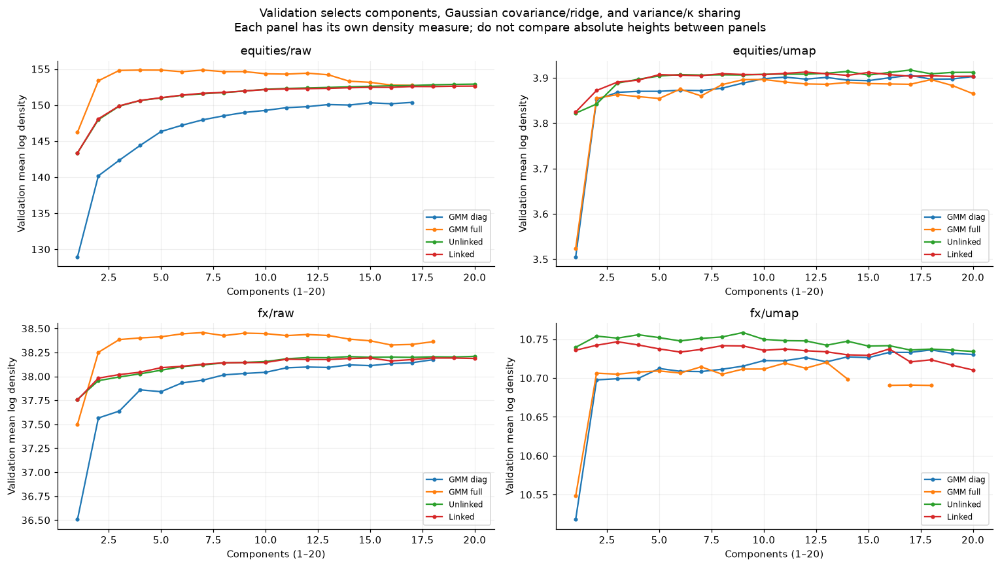

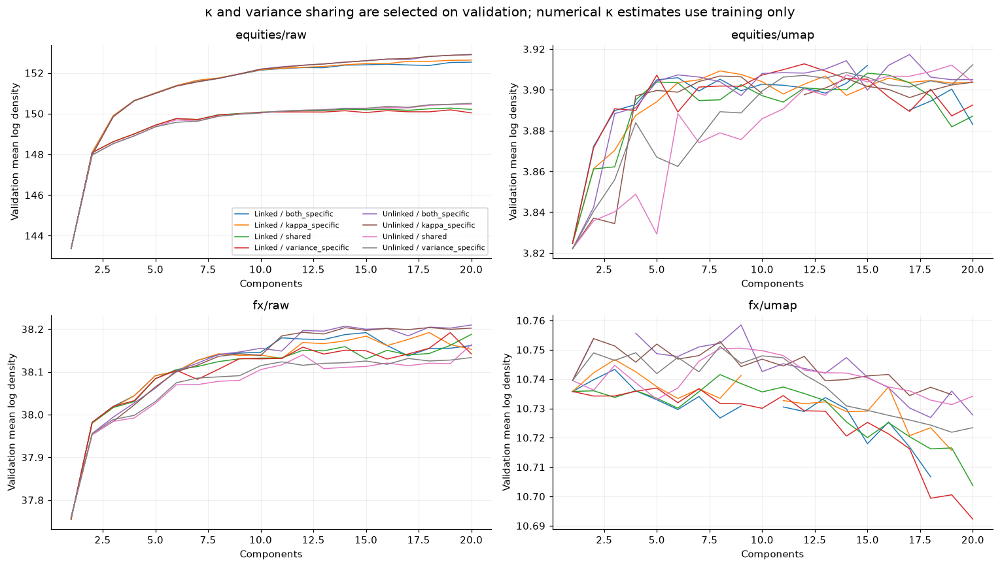

,case,family,matrix_toggle,k,sharing,regularization,parameters,validation_mean_loglik,component_boundary
0,equities/raw,GMM,diag,17,shared,0.0,1716,150.36956,False
1,equities/raw,GMM,full,4,shared,0.0,5303,154.85647,False
2,equities/raw,Linked,diag,20,kappa_specific,0.0,2040,152.63334,True
3,equities/raw,Linked,full,20,kappa_specific,0.0,2040,152.63334,True
4,equities/raw,Unlinked,diag,20,kappa_specific,0.0,1040,152.90524,True
5,equities/raw,Unlinked,full,20,kappa_specific,0.0,1040,152.90524,True
6,equities/umap,GMM,diag,17,shared,0.0,118,3.90557,False
7,equities/umap,GMM,full,10,shared,0.0,99,3.89648,False
8,equities/umap,Linked,diag,12,variance_specific,0.0,96,3.91275,False
9,equities/umap,Linked,full,12,variance_specific,0.0,96,3.91275,False


In [20]:
mixture_report.validation_plot(MIXTURE_TABLES, MIXTURE_RUN)
mixture_report.sharing_plot(MIXTURE_TABLES, MIXTURE_RUN)
display(MIXTURE_TABLES["frozen_selections"][["case","family","matrix_toggle","k","sharing","regularization","parameters","validation_mean_loglik","component_boundary"]].round(5))

## 17. Test performance, AIC and BIC

Selected architectures are refitted on development data; test scores do not replace failed refits or alter selections. AIC = 2p − 2ℓ and BIC = p log(n) − 2ℓ use **development fitted-sample total likelihood**, not test likelihood. Cylinder densities include the correct −d log(radius) Jacobian. Test log density and paired gains have 1,500 circular block-bootstrap replicates, with 20-session primary blocks and 5/60-session sensitivity.

All three families use the same density measure **within a representation**. Absolute likelihood/AIC/BIC cannot compare raw returns with the dimension-reducing UMAP representation, or equities with FX. UMAP information criteria condition on the fixed encoder and do not count its nonparametric fitting capacity. Diagonal Gaussian fits also depend on the chosen coordinate axes; spherical output alone does not remove that dependence.

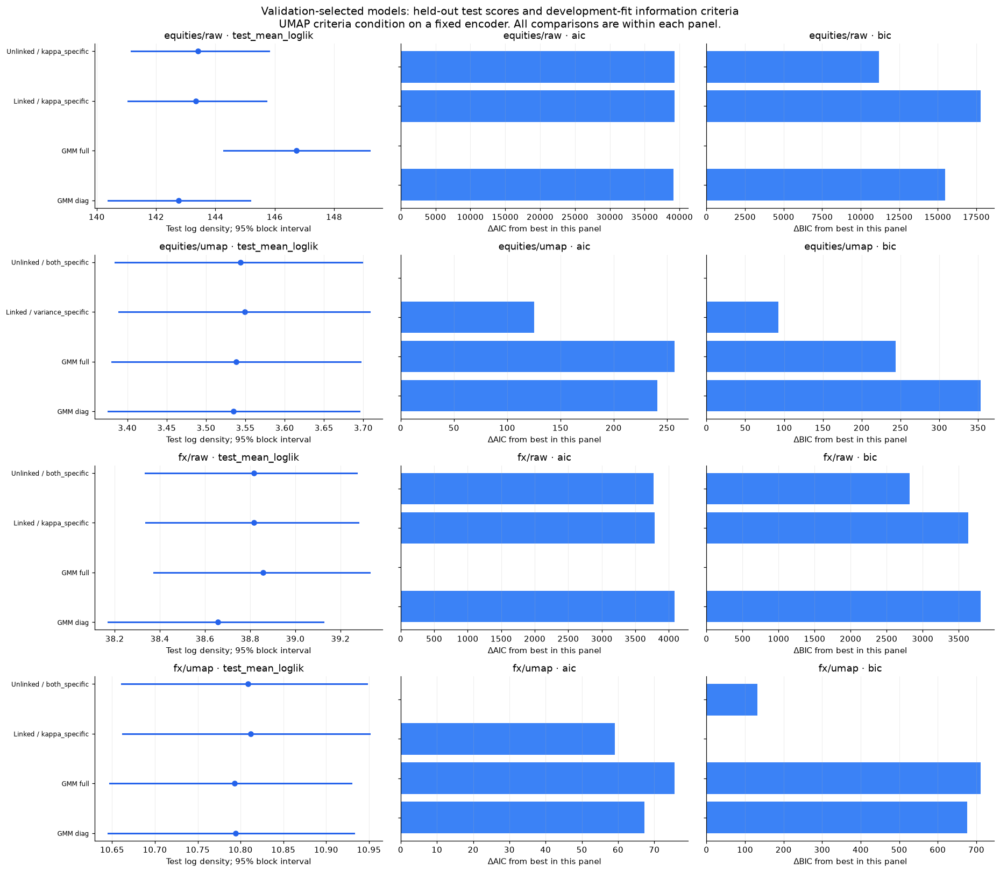

,case,full_components,diagonal_components,full_parameters,diagonal_parameters,mean,lower,upper
0,equities/raw,4,17,5303,1716,3.9672,3.5283,4.4133
1,equities/umap,10,17,99,118,0.0037,-0.0089,0.0159
2,fx/raw,7,18,384,341,0.2003,0.1454,0.2551
3,fx/umap,13,18,129,125,-0.0015,-0.0132,0.0101


,case,family,matrix_toggle,k,sharing,test_mean_loglik,aic,bic
0,equities/raw,GMM,diag,17,shared,142.7540,-1.578322e+06,-1.567007e+06
1,equities/raw,GMM,full,4,shared,146.7212,-1.617444e+06,-1.582477e+06
2,equities/raw,Linked,diag,20,kappa_specific,143.3419,-1.578165e+06,-1.564714e+06
3,equities/raw,Linked,full,20,kappa_specific,143.3419,-1.578165e+06,-1.564714e+06
4,equities/raw,Unlinked,diag,20,kappa_specific,143.4050,-1.578159e+06,-1.571301e+06
5,equities/raw,Unlinked,full,20,kappa_specific,143.4050,-1.578159e+06,-1.571301e+06
6,equities/umap,GMM,diag,17,shared,3.5350,-3.716354e+04,-3.638547e+04
7,equities/umap,GMM,full,10,shared,3.5387,-3.714738e+04,-3.649459e+04
8,equities/umap,Linked,diag,12,variance_specific,3.5494,-3.727903e+04,-3.664602e+04
9,equities/umap,Linked,full,12,variance_specific,3.5494,-3.727903e+04,-3.664602e+04


,case,candidate,baseline,block,mean,lower,upper
1,equities/raw,gmm_k17_diag_1e-07,gmm_k04_full_1e-07,20,-3.9672,-4.4133,-3.5283
4,equities/raw,gmm_k04_full_1e-07,gmm_k04_full_1e-07,20,0.0000,0.0000,0.0000
7,equities/raw,linked_kappa_specific_k20,gmm_k04_full_1e-07,20,-3.3793,-3.7655,-2.9955
10,equities/raw,unlinked_kappa_specific_k20,gmm_k04_full_1e-07,20,-3.3162,-3.7120,-2.9337
13,equities/umap,gmm_k17_diag_1e-07,gmm_k17_diag_1e-07,20,0.0000,0.0000,0.0000
16,equities/umap,gmm_k10_full_1e-06,gmm_k17_diag_1e-07,20,0.0037,-0.0089,0.0159
19,equities/umap,linked_variance_specific_k12,gmm_k17_diag_1e-07,20,0.0144,0.0034,0.0252
22,equities/umap,unlinked_both_specific_k17,gmm_k17_diag_1e-07,20,0.0090,-0.0030,0.0206
25,fx/raw,gmm_k18_diag_1e-07,gmm_k07_full_1e-07,20,-0.2003,-0.2551,-0.1454
28,fx/raw,gmm_k07_full_1e-07,gmm_k07_full_1e-07,20,0.0000,0.0000,0.0000


In [21]:
mixture_report.result_plot(MIXTURE_TABLES, MIXTURE_RUN)
covariance_effect = mixture_report.covariance_effects(MIXTURE_TABLES)
covariance_effect.to_csv(MIXTURE_RUN/"covariance_effects.csv",index=False)
display(covariance_effect.round(4))
display(MIXTURE_TABLES["test_results"][["case","family","matrix_toggle","k","sharing","test_mean_loglik","aic","bic"]].round(4))
display(MIXTURE_TABLES["paired_gains"].query("block == 20").round(4))

## 18. Selected concentrations and inference checks

The expected directional cosine A_d(κ) adjusts interpretation for dimension: the vMF ambient dimensions are 50 for raw equities, 9 for raw FX, and 3 for UMAP (sphere dimensions 49, 8, and 2). Comparing bare κ across these dimensions is misleading. Shared κ applies to all components; component-specific κ is listed separately.

Checks below verify the selected validation maxima, identical matrix aliases, saved daily test scores, analytic parameter counts, and fitted-sample AIC/BIC against independently recomputed likelihoods and scikit-learn where applicable.

In [22]:
kappa_diagnostics = mixture_report.kappa_table(MIXTURE_TABLES)
kappa_diagnostics.to_csv(MIXTURE_RUN/"kappa_diagnostics.csv",index=False)
display(kappa_diagnostics.round(4))
display(pd.Series(mixture_report.verify(MIXTURE_TABLES,MIXTURE_RUN),name="verification").to_frame())

,case,candidate,component,kappa,sharing,dimensions,expected_direction_cosine
0,equities/raw,linked_kappa_specific_k20,0,13.2199,kappa_specific,50,0.2486
1,equities/raw,linked_kappa_specific_k20,1,87.3265,kappa_specific,50,0.7569
2,equities/raw,linked_kappa_specific_k20,2,219.1261,kappa_specific,50,0.8942
3,equities/raw,linked_kappa_specific_k20,3,27.5825,kappa_specific,50,0.4452
4,equities/raw,linked_kappa_specific_k20,4,39.7372,kappa_specific,50,0.5551
...,...,...,...,...,...,...,...
224,fx/umap,unlinked_both_specific_k09,4,2.0888,both_specific,3,0.5524
225,fx/umap,unlinked_both_specific_k09,5,2.6486,both_specific,3,0.6325
226,fx/umap,unlinked_both_specific_k09,6,7.4131,both_specific,3,0.8651
227,fx/umap,unlinked_both_specific_k09,7,2.0317,both_specific,3,0.5428


,verification
rows,24
distinct_fitted_comparisons,16
matrix_aliases_verified,True
validation_selection_verified,True
aic_bic_verified,True
test_daily_verified,True
test_used_for_selection,False
study_sha256,d15b7ceac7c76d7b979e89d6c559631785fea5ad905a6e...


### Common-target comparison across representations

Original vector magnitude is retained by the transformation. We therefore score the same held-out **log magnitude** under every frozen model's marginal distribution using lower-is-better CRPS: `E|S-y| − 0.5 E|S-S′|`. This is the loss form of the [Gneiting–Raftery proper scoring rule](https://sites.stat.washington.edu/raftery/Research/PDF/Gneiting2007jasa.pdf).

Generate 60,000 log-magnitude samples per fitted model using three fixed seeds. Report sampling sensitivity and paired 5/20/60-session block intervals. Positive raw-minus-UMAP CRPS means improved magnitude calibration in the UMAP pipeline. No model is reselected using this secondary score. Its scope is the common retained magnitude marginal; the earlier neighborhood analysis evaluates directional structure.

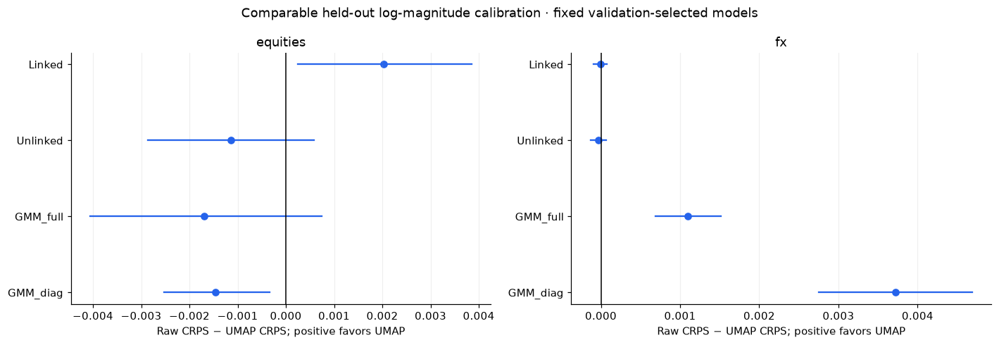

,case,model,candidate,crps,samples,seed_min,seed_max
0,equities/raw,GMM_diag,gmm_k17_diag_1e-07,0.22163,60000,0.22151,0.22185
1,equities/raw,GMM_full,gmm_k04_full_1e-07,0.22153,60000,0.22106,0.22179
2,equities/raw,Linked,linked_kappa_specific_k20,0.22413,60000,0.22369,0.22441
3,equities/raw,Unlinked,unlinked_kappa_specific_k20,0.22165,60000,0.22145,0.22179
4,equities/umap,GMM_diag,gmm_k17_diag_1e-07,0.22309,60000,0.22269,0.22371
5,equities/umap,GMM_full,gmm_k10_full_1e-06,0.22323,60000,0.22308,0.22331
6,equities/umap,Linked,linked_variance_specific_k12,0.22211,60000,0.22179,0.22244
7,equities/umap,Unlinked,unlinked_both_specific_k17,0.22279,60000,0.22254,0.22295
8,fx/raw,GMM_diag,gmm_k18_diag_1e-07,0.29649,60000,0.29529,0.29717
9,fx/raw,GMM_full,gmm_k07_full_1e-07,0.29390,60000,0.29362,0.29442


,market,model,block,positive_means,mc_seed_min,mc_seed_max,mean,lower,upper
1,equities,GMM_diag,20,UMAP has lower log-magnitude CRPS,-0.00220,-0.00106,-0.00146,-0.00253,-0.00034
4,equities,GMM_full,20,UMAP has lower log-magnitude CRPS,-0.00225,-0.00129,-0.00170,-0.00406,0.00074
7,equities,Unlinked,20,UMAP has lower log-magnitude CRPS,-0.00126,-0.00108,-0.00114,-0.00286,0.00058
10,equities,Linked,20,UMAP has lower log-magnitude CRPS,0.00125,0.00253,0.00203,0.00025,0.00386
13,fx,GMM_diag,20,UMAP has lower log-magnitude CRPS,0.00173,0.00518,0.00372,0.00275,0.00469
16,fx,GMM_full,20,UMAP has lower log-magnitude CRPS,0.00072,0.00137,0.00110,0.00069,0.00151
19,fx,Unlinked,20,UMAP has lower log-magnitude CRPS,-0.00059,0.00089,-0.00003,-0.00013,0.00007
22,fx,Linked,20,UMAP has lower log-magnitude CRPS,-0.00113,0.00176,-0.00001,-0.00009,0.00008


In [23]:
magnitude_scores, magnitude_gains = mixture_report.common_magnitude(MIXTURE_TABLES,MIXTURE_RUN)
display(magnitude_scores.round(5))
display(magnitude_gains.query("block == 20").round(5))

## 19. Inferences about the transformation

These conclusions distinguish the effects on model rankings and preferred complexity from unsupported cross-space density comparisons. Best-family comparisons include changes in component count and sharing structure; they do not identify a causal effect of spherical geometry. Both markets are independent analyses of previously inspected historical periods.

In [24]:
mixture_conclusions = mixture_report.conclusions(MIXTURE_TABLES) + chr(10)*2 + "Common retained-magnitude comparison:" + chr(10)*2 + mixture_report.magnitude_conclusions(magnitude_gains)
display(Markdown(mixture_conclusions))
(MIXTURE_RUN/"conclusions.md").write_text(mixture_conclusions+"\n")
mixture_status=json.loads((MIXTURE_RUN/"status.json").read_text())
mixture_status["notebook"]="executed"
experiment.write_json(MIXTURE_RUN/"status.json",mixture_status)
print("Saved trial ledgers, frozen selections, test scores, covariance matrices, κ diagnostics and figures:",MIXTURE_RUN)

- **equities/raw:** validation selected full covariance for normal GMM (K=4). Unlinked: K=20, kappa_specific; test gain versus the validation-selected normal GMM -3.316 nats (95% interval -3.712, -2.934). Linked: K=20, kappa_specific; test gain versus the validation-selected normal GMM -3.379 nats (95% interval -3.765, -2.996). Lowest development AIC: GMM/full; lowest BIC: GMM/full. At least one winner reaches K=20; its component optimum is unresolved beyond the declared grid.

- **equities/umap:** validation selected diag covariance for normal GMM (K=17). Unlinked: K=17, both_specific; test gain versus the validation-selected normal GMM +0.009 nats (95% interval -0.003, +0.021). Linked: K=12, variance_specific; test gain versus the validation-selected normal GMM +0.014 nats (95% interval +0.003, +0.025). Lowest development AIC: Unlinked/both_specific; lowest BIC: Unlinked/both_specific.

- **fx/raw:** validation selected full covariance for normal GMM (K=7). Unlinked: K=20, both_specific; test gain versus the validation-selected normal GMM -0.041 nats (95% interval -0.105, +0.019). Linked: K=18, kappa_specific; test gain versus the validation-selected normal GMM -0.042 nats (95% interval -0.101, +0.016). Lowest development AIC: GMM/full; lowest BIC: GMM/full. At least one winner reaches K=20; its component optimum is unresolved beyond the declared grid.

- **fx/umap:** validation selected diag covariance for normal GMM (K=18). Unlinked: K=9, both_specific; test gain versus the validation-selected normal GMM +0.014 nats (95% interval +0.001, +0.027). Linked: K=3, kappa_specific; test gain versus the validation-selected normal GMM +0.018 nats (95% interval +0.004, +0.031). Lowest development AIC: Unlinked/both_specific; lowest BIC: Linked/kappa_specific.

**equities transformation comparison:** highest observed test-density model within raw space: GMM/full; within UMAP space: Linked/variance_specific. This is a descriptive ranking of frozen candidates, not a test-based hyperparameter choice.

**fx transformation comparison:** highest observed test-density model within raw space: GMM/full; within UMAP space: Linked/kappa_specific. This is a descriptive ranking of frozen candidates, not a test-based hyperparameter choice.

**equities/raw, full versus diagonal normal GMM:** validated K=4 (p=5303) versus K=17 (p=1716); test gain +3.967 nats (95% interval +3.528, +4.413). This comparison includes the separately selected component counts.

**equities/umap, full versus diagonal normal GMM:** validated K=10 (p=99) versus K=17 (p=118); test gain +0.004 nats (95% interval -0.009, +0.016). This comparison includes the separately selected component counts.

**fx/raw, full versus diagonal normal GMM:** validated K=7 (p=384) versus K=18 (p=341); test gain +0.200 nats (95% interval +0.145, +0.255). This comparison includes the separately selected component counts.

**fx/umap, full versus diagonal normal GMM:** validated K=13 (p=129) versus K=18 (p=125); test gain -0.002 nats (95% interval -0.013, +0.010). This comparison includes the separately selected component counts.

These within-space rankings and selected complexities describe the effect of changing representation. It does not establish improved density modeling of the original returns: UMAP discards directional dimensions, and cross-space likelihood/AIC/BIC differences are not comparable. Differences between best linked/unlinked fits also include selected K and sharing changes, so they do not isolate the link coefficient alone. Diagonal/full cylinders are identical scalar-covariance models. κ values across dimensions should be interpreted using the reported expected direction cosine, not their numerical sizes alone. These are retrospective, conditional model comparisons, with serial dependence and mixture singularities limiting classical AIC/BIC interpretation.

Common retained-magnitude comparison:

- **equities / GMM_diag:** raw features improve retained-magnitude calibration. Raw-minus-UMAP CRPS -0.00146, 95% interval [-0.00253, -0.00034]; separate-seed estimates [-0.00220, -0.00106].
- **equities / GMM_full:** the comparison is inconclusive after test and Monte Carlo sensitivity checks. Raw-minus-UMAP CRPS -0.00170, 95% interval [-0.00406, +0.00074]; separate-seed estimates [-0.00225, -0.00129].
- **equities / Unlinked:** the comparison is inconclusive after test and Monte Carlo sensitivity checks. Raw-minus-UMAP CRPS -0.00114, 95% interval [-0.00286, +0.00058]; separate-seed estimates [-0.00126, -0.00108].
- **equities / Linked:** UMAP improves retained-magnitude calibration. Raw-minus-UMAP CRPS +0.00203, 95% interval [+0.00025, +0.00386]; separate-seed estimates [+0.00125, +0.00253].
- **fx / GMM_diag:** UMAP improves retained-magnitude calibration. Raw-minus-UMAP CRPS +0.00372, 95% interval [+0.00275, +0.00469]; separate-seed estimates [+0.00173, +0.00518].
- **fx / GMM_full:** UMAP improves retained-magnitude calibration. Raw-minus-UMAP CRPS +0.00110, 95% interval [+0.00069, +0.00151]; separate-seed estimates [+0.00072, +0.00137].
- **fx / Unlinked:** the comparison is inconclusive after test and Monte Carlo sensitivity checks. Raw-minus-UMAP CRPS -0.00003, 95% interval [-0.00013, +0.00007]; separate-seed estimates [-0.00059, +0.00089].
- **fx / Linked:** the comparison is inconclusive after test and Monte Carlo sensitivity checks. Raw-minus-UMAP CRPS -0.00001, 95% interval [-0.00009, +0.00008]; separate-seed estimates [-0.00113, +0.00176].

Saved trial ledgers, frozen selections, test scores, covariance matrices, κ diagnostics and figures: /Users/shashwatroy/VSCode Projects/Thesis/umap_mixture_results/20261104T220523_452679Z
